In [7]:
import os
print("Current Folder:", os.getcwd())

Current Folder: C:\Users\ASUS


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Agar file current folder mein hai toh sirf naam likhein:
df = pd.read_csv('cleaned_sales_dataset.csv')

# Date column ko datetime format mein convert karein
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (1000, 12)


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


In [10]:
# 1. Numerical columns ke summary statistics (Mean, Std, Min, Max, Quantiles)
print("--- Numerical Fields Statistics ---")
print(df[['Age', 'Quantity', 'Unit_Price', 'Total_Sales']].describe())

# 2. Categorical columns ka breakdown (Gender, City, Category, Product)
print("\n--- Categorical Fields Breakdown ---")
for col in ['Gender', 'City', 'Category', 'Product']:
    print(f"\nValue Counts for {col}:")
    print(df[col].value_counts())

--- Numerical Fields Statistics ---
               Age     Quantity    Unit_Price    Total_Sales
count  1000.000000  1000.000000   1000.000000    1000.000000
mean     41.353000     5.435000  25486.783410  139399.439650
std      13.683626     2.838632  14179.402361  114100.051546
min      18.000000     1.000000    145.780000     437.340000
25%      30.000000     3.000000  13895.722500   47066.632500
50%      41.000000     5.000000  25398.740000  108594.025000
75%      53.000000     8.000000  37512.382500  203722.882500
max      65.000000    10.000000  49997.530000  493677.500000

--- Categorical Fields Breakdown ---

Value Counts for Gender:
Gender
Male      511
Female    489
Name: count, dtype: int64

Value Counts for City:
City
Patna        148
Kolkata      133
Mumbai       131
Hyderabad    125
Delhi        125
Bengaluru    122
Gaya         117
Pune          99
Name: count, dtype: int64

Value Counts for Category:
Category
Electronics    354
Education      178
Furniture      159
Fashi

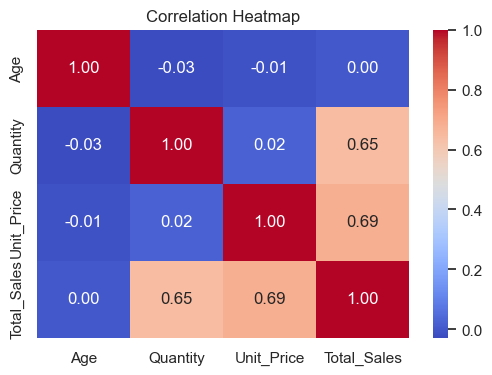

In [11]:
# 1. Correlation Heatmap (Age, Quantity, Unit_Price, Total_Sales)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
corr = df[['Age', 'Quantity', 'Unit_Price', 'Total_Sales']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

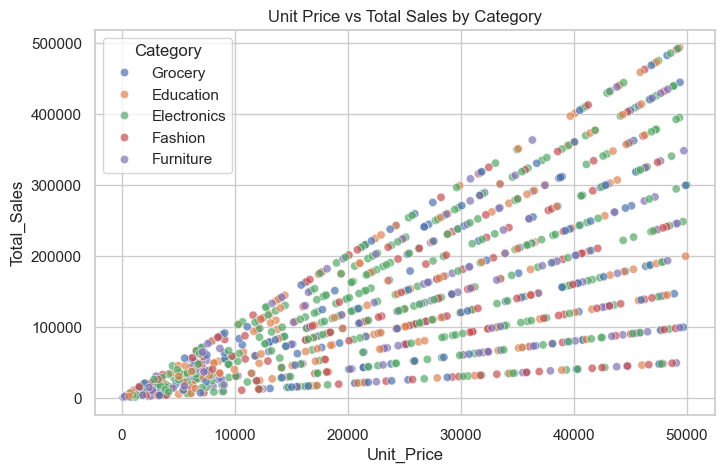

In [12]:
# 2. Scatter Plot: Unit Price vs Total Sales by Category
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Unit_Price', y='Total_Sales', hue='Category', alpha=0.7)
plt.title('Unit Price vs Total Sales by Category')
plt.show()

In [13]:
# Dashboard Key Performance Indicators (KPIs) Summary
total_revenue = df['Total_Sales'].sum()
total_orders = df['Order_ID'].count()
avg_order_value = df['Total_Sales'].mean()
top_category = df.groupby('Category')['Total_Sales'].sum().idxmax()

print("=== DASHBOARD KPI METRICS ===")
print(f"Total Revenue       : ₹{total_revenue:,.2f}")
print(f"Total Orders        : {total_orders}")
print(f"Average Order Value : ₹{avg_order_value:,.2f}")
print(f"Top Performing Cat  : {top_category}")

=== DASHBOARD KPI METRICS ===
Total Revenue       : ₹139,399,439.65
Total Orders        : 1000
Average Order Value : ₹139,399.44
Top Performing Cat  : Electronics


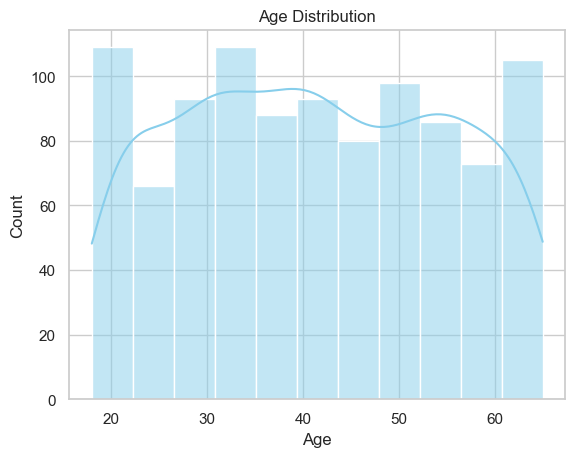

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sirf Age ka distribution dekhne ke liye chhota code
sns.histplot(df['Age'], kde=True, color='skyblue')
plt.title('Age Distribution')
plt.show()

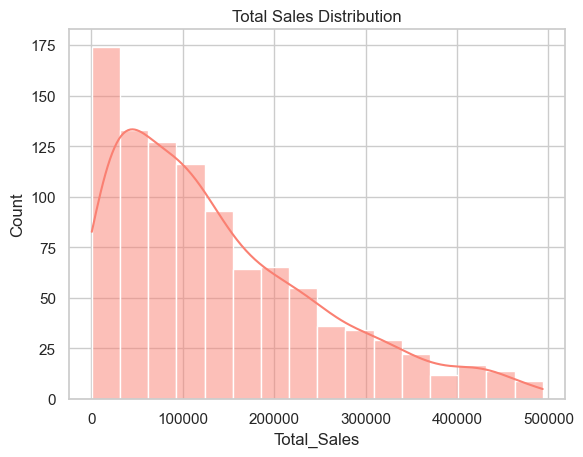

In [17]:
# Sirf Total Sales ka distribution dekhne ke liye
sns.histplot(df['Total_Sales'], kde=True, color='salmon')
plt.title('Total Sales Distribution')
plt.show()

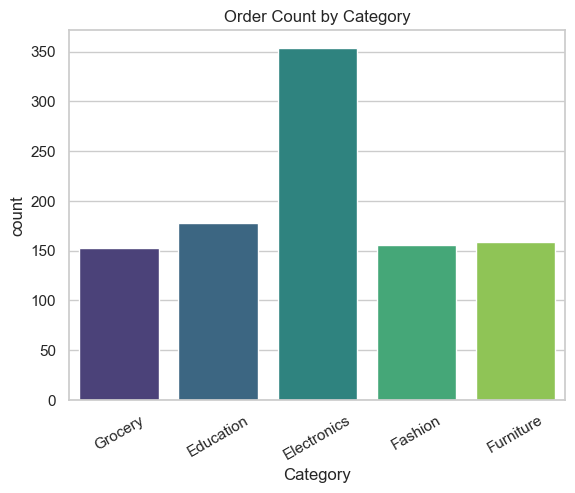

In [23]:
# Sirf Category wise orders dekhne ke liye bar chart
sns.countplot(data=df, x='Category',hue='Category' , palette='viridis' , legend=False)
plt.title('Order Count by Category')
plt.xticks(rotation=30)
plt.show()

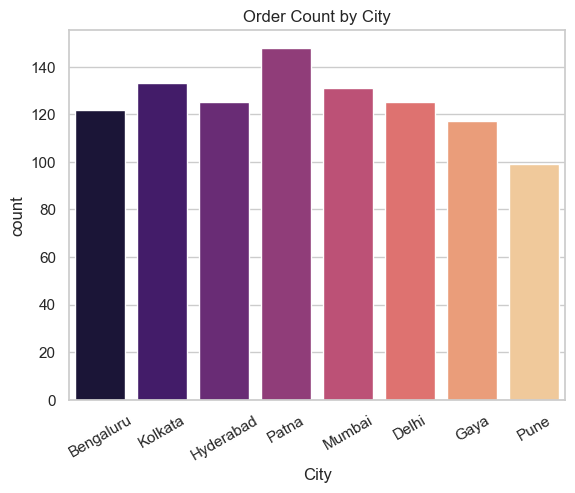

In [22]:
sns.countplot(data=df, x='City', hue='City', palette='magma', legend=False)
plt.title('Order Count by City')
plt.xticks(rotation=30)
plt.show()